# 00 · Data audit

**Milestone M0.** This notebook checks that the downloaded Binance Vision spot klines are complete, verified and correctly parsed before anything is modelled. The logic lives in `src/ebmregime/data/`; this notebook only runs it and shows the results.

*Data: Binance Vision public archive (https://data.binance.vision), CC BY-NC-SA 4.0. The figures and tables below are derived works under the same licence. See `DATA_NOTICE.md`.*

Prepare the data first:
```
python scripts/download_data.py
python scripts/build_bars.py
```

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ebmregime.config import load_config, repo_path
from ebmregime.data import store
from ebmregime.data.audit import by_year, runs, summarize, unit_switch
from ebmregime.data.download import manifest_hash, verify_against_manifest

pd.set_option("display.width", 140)
CFG = load_config("data")
SYMBOLS = list(CFG["symbols"])
MANIFEST = repo_path(CFG["paths"]["manifest"])
info = json.loads((store.interim_dir() / "build_info.json").read_text())
print("manifest hash:", manifest_hash(MANIFEST)[:16], "| build used:", info["manifest_hash"][:16])

manifest hash: bf30026133152753 | build used: bf30026133152753


## 1. Files and checksums
Every zip was checked against its published SHA-256 when it was downloaded. Here every file is hashed again against the manifest.

In [2]:
man = pd.read_csv(MANIFEST)
bad = verify_against_manifest(MANIFEST, repo_path(CFG["paths"]["raw"]))
print("files failing re-verification:", len(bad))
(man.assign(MB=man.size_bytes / 1e6)
    .groupby(["symbol", "interval"])
    .agg(files=("file", "size"), first=("file", "min"), last=("file", "max"), MB=("MB", "sum"))
    .round(1))

files failing re-verification: 0


files                    first                     last    MB
symbol  interval                                                               
BTCUSDT 15m         111  BTCUSDT-15m-2017-08.zip  BTCUSDT-15m-2026-10.zip  17.9
        1h          111   BTCUSDT-1h-2017-08.zip   BTCUSDT-1h-2026-10.zip   4.7
ETHUSDT 15m         111  ETHUSDT-15m-2017-08.zip  ETHUSDT-15m-2026-10.zip  16.8
        1h          111   ETHUSDT-1h-2017-08.zip   ETHUSDT-1h-2026-10.zip   4.5
SOLUSDT 15m          75  SOLUSDT-15m-2020-08.zip  SOLUSDT-15m-2026-10.zip  10.1
        1h           75   SOLUSDT-1h-2020-08.zip   SOLUSDT-1h-2026-10.zip   2.7
XRPUSDT 15m         102  XRPUSDT-15m-2018-05.zip  XRPUSDT-15m-2026-10.zip  13.7
        1h          102   XRPUSDT-1h-2018-05.zip   XRPUSDT-1h-2026-10.zip   3.7

## 2. Timestamp units
Spot files switch from milliseconds to **microseconds** from the 2025-01 file onward. The parser detects the unit from the magnitude of each file's values and rejects files that mix units.

In [3]:
pd.DataFrame({iv: {s: unit_switch(store.file_units(s, iv)) for s in SYMBOLS} for iv in ["15m", "1h"]})

,15m,1h
BTCUSDT,2025-01,2025-01
ETHUSDT,2025-01,2025-01
XRPUSDT,2025-01,2025-01
SOLUSDT,2025-01,2025-01


## 3. Coverage and gaps, full history
Counts are against a perfect UTC grid between each symbol's first and last bar. *Invalid* means missing, off-grid, truncated or an outage placeholder (zero volume, O=H=L=C).

In [4]:
rows = []
for s in SYMBOLS:
    for kind in ["grid_15m", "archive_1h"]:
        rows.append({"symbol": s, "grid": kind, **summarize(store.load(kind, s))})
summary = pd.DataFrame(rows).set_index(["symbol", "grid"])
summary

first_bar                  last_bar  expected  present  missing  missing_runs  placeholder  truncated  \
symbol  grid                                                                                                                               
BTCUSDT grid_15m   2017-08-17 04:00:00+00:00 2026-10-31 23:45:00+00:00    322832   322270      562            32           60         16   
        archive_1h 2017-08-17 04:00:00+00:00 2026-10-31 23:00:00+00:00     80708    80581      127            28            4         15   
ETHUSDT grid_15m   2017-08-17 04:00:00+00:00 2026-10-31 23:45:00+00:00    322832   322270      562            32          154         16   
        archive_1h 2017-08-17 04:00:00+00:00 2026-10-31 23:00:00+00:00     80708    80581      127            28            6         15   
XRPUSDT grid_15m   2018-05-04 08:00:00+00:00 2026-10-31 23:45:00+00:00    297856   297468      388            26           17          9   
        archive_1h 2018-05-04 08:00:00+00:00 2026-10-31 23:00:00+00:00     74464    74377       87            25            4          9   
SOLUSDT grid_15m   2020-08-11 06:00:00+00:00 2026-10-31 23:45:00+00:00    218184   218091       93            10           13          6   
        archive_1h 2020-08-11 06:00:00+00:00 2026-10-31 23:00:00+00:00     54546    54527       19            10            3          6   

                    off_grid  invalid  
symbol  grid                           
BTCUSDT grid_15m          81      714  
        archive_1h        43      184  
ETHUSDT grid_15m          81      808  
        archive_1h        43      186  
XRPUSDT grid_15m           0      410  
        archive_1h         0       96  
SOLUSDT grid_15m           0      109  
        archive_1h         0       25

In [5]:
# Outages are exchange-wide: compare the timestamps of the missing 1h bars across symbols.
miss = {s: set(store.load("archive_1h", s).query("~present").index) for s in SYMBOLS}
common_start = max(store.load("archive_1h", s).index[0] for s in SYMBOLS)
for s in SYMBOLS:
    own = {t for t in miss[s] if t >= common_start}
    others = set().union(*(miss[o] for o in SYMBOLS if o != s))
    print(f"{s}: {len(own)} missing 1h bars since {common_start:%Y-%m-%d}, "
          f"{len(own & others)} of them also missing in another symbol")

BTCUSDT: 19 missing 1h bars since 2020-08-11, 19 of them also missing in another symbol
ETHUSDT: 19 missing 1h bars since 2020-08-11, 19 of them also missing in another symbol
XRPUSDT: 19 missing 1h bars since 2020-08-11, 19 of them also missing in another symbol
SOLUSDT: 19 missing 1h bars since 2020-08-11, 19 of them also missing in another symbol


In [6]:
g = store.load("grid_15m", "BTCUSDT")
display(by_year(g).T)
runs(~g["valid"]).head(10).assign(hours=lambda d: d.n_bars / 4)

year,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
missing,32,261,117,82,65,0,5,0,0,0
invalid,77,346,121,87,73,0,10,0,0,0
expected,13136,35040,35040,35136,35040,35040,35040,35136,35040,29184


,start,n_bars,hours
0,2018-02-08 00:15:00+00:00,216,54.00
1,2018-06-26 02:00:00+00:00,40,10.00
2,2019-05-15 03:00:00+00:00,40,10.00
3,2019-08-15 02:00:00+00:00,32,8.00
4,2018-07-04 00:15:00+00:00,31,7.75
5,2017-09-06 15:45:00+00:00,29,7.25
6,2018-11-14 02:00:00+00:00,28,7.00
7,2019-03-12 02:00:00+00:00,24,6.00
8,2020-02-19 11:30:00+00:00,24,6.00
9,2021-04-25 04:00:00+00:00,19,4.75


## 4. 15m → 1h aggregation cross-check
We build 1h bars from 15m sub-bars, so that realised variance can use 15-minute returns. An hour is valid only if all four sub-bars are valid. Every hour that is valid both in our aggregation and in the archive's own 1h files is compared. In a handful of hours per symbol the archive's own 1h file reports more volume and trades than the sum of its 15m files, and in one XRP hour a slightly different close. This is an inconsistency inside the archive, not a parsing error. We cannot tell which file is right, so the rule is (DECISIONS D-40): hours whose prices disagree become **invalid**; hours where only volume disagrees keep their prices and are flagged `volume_suspect`, and volume features treat them as missing.

In [7]:
display(pd.concat({s: store.crosscheck_table(s).set_index("column")["mismatches"] for s in SYMBOLS}, axis=1))
sus = []
for s in SYMBOLS:
    b, a, g = store.load("bars_1h", s), store.load("archive_1h", s), store.load("grid_15m", s)
    for t in b.index[b["volume_suspect"]]:
        sus.append({"symbol": s, "hour": t, "volume_from_15m": b.at[t, "volume"], "volume_archive_1h": a.at[t, "volume"],
                    "trades_from_15m": int(b.at[t, "n_trades"]), "trades_archive_1h": int(a.at[t, "n_trades"]),
                    "price_conflict": bool(b.at[t, "price_conflict"])})
sus = pd.DataFrame(sus).assign(ratio=lambda d: (d.volume_archive_1h / d.volume_from_15m).round(3))
sus

,BTCUSDT,ETHUSDT,XRPUSDT,SOLUSDT
column,,,,
open,0,0,0,0
high,0,0,0,0
low,0,0,0,0
close,0,0,1,0
volume,8,7,4,4
quote_volume,8,7,4,4
taker_buy_base,6,7,4,4
taker_buy_quote,6,7,4,4
n_trades,8,7,4,4


,symbol,hour,volume_from_15m,volume_archive_1h,trades_from_15m,trades_archive_1h,price_conflict,ratio
0,BTCUSDT,2017-12-04 09:00:00+00:00,5.538777e+01,8.410602e+01,737,920,False,1.518
1,BTCUSDT,2018-02-07 06:00:00+00:00,1.483559e+03,1.484335e+03,13801,13823,False,1.001
2,BTCUSDT,2018-03-04 14:00:00+00:00,4.837403e+02,5.096021e+02,5956,6233,False,1.053
3,BTCUSDT,2018-03-20 03:00:00+00:00,1.916023e+03,1.917752e+03,11745,11760,False,1.001
4,BTCUSDT,2018-06-20 03:00:00+00:00,5.570064e+02,5.634868e+02,4581,4596,False,1.012
5,BTCUSDT,2021-04-22 02:00:00+00:00,8.551331e+03,8.567790e+03,164658,165036,False,1.002
6,BTCUSDT,2021-04-23 01:00:00+00:00,1.165386e+04,1.166763e+04,276006,276379,False,1.001
7,BTCUSDT,2021-04-23 02:00:00+00:00,1.534595e+04,1.548224e+04,346211,350744,False,1.009
8,ETHUSDT,2017-12-04 09:00:00+00:00,3.921489e+02,4.311055e+02,635,718,False,1.099
9,ETHUSDT,2018-03-04 14:00:00+00:00,8.196653e+02,8.481672e+02,1965,2053,False,1.035


## 5. Analysis range
Model windows start at `analysis_start` (2018-06-01; SOL 2020-09-01) and end with the 2026-10 month. Invalid hours inside this range are masked in M1: features whose lookback touches them and labels whose horizon touches them.

In [8]:
rng = []
for s in SYMBOLS:
    b = store.load("bars_1h", s).loc[CFG["symbols"][s]["analysis_start"]:]
    r = runs(~b["valid"])
    rng.append({"symbol": s, "start": b.index[0], "end": b.index[-1], "hours": len(b),
                "invalid": int((~b["valid"]).sum()), "invalid_%": round(100 * (~b["valid"]).mean(), 3),
                "longest_invalid_run_h": int(r.n_bars.max()) if len(r) else 0,
                "at": r.start.iloc[0] if len(r) else None})
pd.DataFrame(rng).set_index("symbol")

,start,end,hours,invalid,invalid_%,longest_invalid_run_h,at
symbol,,,,,,,
BTCUSDT,2018-06-01 00:00:00+00:00,2026-10-31 23:00:00+00:00,73800,113,0.153,10,2018-06-26 02:00:00+00:00
ETHUSDT,2018-06-01 00:00:00+00:00,2026-10-31 23:00:00+00:00,73800,113,0.153,10,2018-06-26 02:00:00+00:00
XRPUSDT,2018-06-01 00:00:00+00:00,2026-10-31 23:00:00+00:00,73800,113,0.153,10,2018-06-26 02:00:00+00:00
SOLUSDT,2020-09-01 00:00:00+00:00,2026-10-31 23:00:00+00:00,54048,32,0.059,6,2021-08-13 01:00:00+00:00


## 6. Volume regime breaks (for the liquidity regime R3 and the volume features)
Venue programmes, such as zero-fee promotions, can shift quote volume and the taker-buy share abruptly. This section lists months where log monthly quote volume moved by more than 1.0 (a factor of about 2.7) from the previous month, or where the median taker-buy share moved by more than 0.05. These are candidate dates only. Each one gets a cause, or is marked as market-driven, before H3 is interpreted.

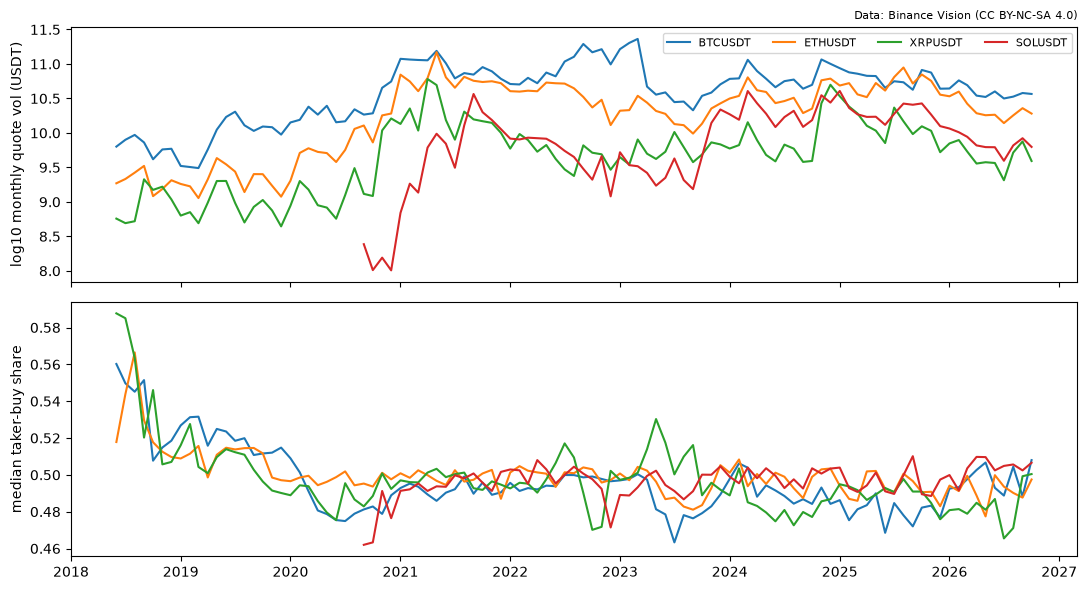

,symbol,month,dlog_qv,d_taker
0,BTCUSDT,2023-04,-1.59,-0.003
1,ETHUSDT,2018-10,-1.01,-0.012
2,ETHUSDT,2021-01,1.30,0.003
3,XRPUSDT,2018-09,1.40,-0.043
4,XRPUSDT,2020-11,2.19,0.012
5,XRPUSDT,2021-04,1.72,0.005
6,XRPUSDT,2021-06,-1.17,-0.005
7,XRPUSDT,2022-09,1.02,-0.019
8,XRPUSDT,2024-11,1.93,0.008
9,XRPUSDT,2025-07,1.18,-0.002


In [9]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
flags = []
for s in SYMBOLS:
    b = store.load("bars_1h", s).loc[CFG["symbols"][s]["analysis_start"]:]
    m = b.groupby(b.index.tz_localize(None).to_period("M"))
    qv = m["quote_volume"].sum()
    tk = (b["taker_buy_quote"] / b["quote_volume"]).groupby(b.index.tz_localize(None).to_period("M")).median()
    axes[0].plot(qv.index.to_timestamp(), np.log10(qv), label=s)
    axes[1].plot(tk.index.to_timestamp(), tk, label=s)
    dq, dt = np.log(qv).diff(), tk.diff()
    for p in qv.index[(dq.abs() > 1.0) | (dt.abs() > 0.05)]:
        flags.append({"symbol": s, "month": str(p), "dlog_qv": round(dq[p], 2), "d_taker": round(dt[p], 3)})
axes[0].set_ylabel("log10 monthly quote vol (USDT)"); axes[1].set_ylabel("median taker-buy share")
axes[0].legend(ncol=4, fontsize=8); axes[0].set_title("Data: Binance Vision (CC BY-NC-SA 4.0)", fontsize=8, loc="right")
plt.tight_layout(); plt.show()
pd.DataFrame(flags)

## 7. M0 acceptance
The same checks are run by `pytest -m data` (`tests/test_data_archive.py`).

In [10]:
checks = {
    "all raw files verify against manifest": len(bad) == 0,
    "BTC 1h archive: 127 missing bars": summary.loc[("BTCUSDT", "archive_1h"), "missing"] == 127,
    "SOL 1h archive: 19 missing bars": summary.loc[("SOLUSDT", "archive_1h"), "missing"] == 19,
    "µs switch at 2025-01 for every symbol and interval":
        all(unit_switch(store.file_units(s, iv)) == "2025-01" for s in SYMBOLS for iv in ["15m", "1h"]),
    "price conflicts with archive 1h are rare (<= 2) and masked":
        all(store.load("bars_1h", s)["price_conflict"].sum() <= 2
            and not (store.load("bars_1h", s)["price_conflict"] & store.load("bars_1h", s)["valid"]).any() for s in SYMBOLS),
    "volume-inconsistent hours flagged, <= 10 per symbol": all(sus.groupby("symbol").size() <= 10),
    "analysis range < 0.5% invalid hours": all(r["invalid_%"] < 0.5 for r in rng),
}
for k, v in checks.items():
    print("PASS" if v else "FAIL", "-", k)
assert all(checks.values())

PASS - all raw files verify against manifest
PASS - BTC 1h archive: 127 missing bars
PASS - SOL 1h archive: 19 missing bars
PASS - µs switch at 2025-01 for every symbol and interval
PASS - price conflicts with archive 1h are rare (<= 2) and masked
PASS - volume-inconsistent hours flagged, <= 10 per symbol
PASS - analysis range < 0.5% invalid hours
